# Встреча 6. Решение, мемо, портфель

**Легенда.** Тест нового чекаута отработал запланированные две недели. Владелец продукта ждёт мемо: внедряем или нет, сколько это денег и чем мы рискуем. Параллельно продакт «Горящих предложений» прислал разрезы по сегментам («смотрите, у low и mid значимо!»), а на квартальном ревью-борде надо объединить шесть тестов портфеля.

Три шага: превратить оценку в решение, не «продать» случайный сегмент и положить результат в портфель так, чтобы следующий тест опирался на честную историю. Вход — вердикт встречи 1: правило «внедряем, если наблюдаемая разница конверсий выше точки безубыточности 0.246 п.п.».

**Разделы**

1. Решение против порога, а не против нуля.
2. Эффект чекаута в метрике и в деньгах.
3. Ловушки интерпретации: ratio-метрики и парадокс Симпсона.
4. Guardrail и решение по ролям метрик.
5. Сегменты без p-hacking.
6. Портфель и ревью-борд.
7. Мемо на страницу.
8. Итог и как было на самом деле.

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

### Библиотеки и параметры кейса

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import chi2, norm, t as student_t
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data')


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

Правило решения зафиксировано до запуска (встреча 1): одностороннее $\alpha = 0.5$ против точки безубыточности, то есть **внедряем, если наблюдаемая разница конверсий выше 0.246 п.п.** Деньги считаем по модели встречи 1: выручка 137 млн ₽ в неделю, затраты на тест, внедрение и год поддержки — 25 млн ₽, горизонт — 52 недели.

Граница non-inferiority для ошибок оплаты тоже записана заранее (встреча 2): рост не больше **+0.2 п.п.** (10% от базовых 2%).

In [2]:
# Вход — вердикт встречи 1
VERDICT = {'alpha': 0.5, 'break_even_pp': 0.246, 'n_b': 21000, 'n_total': 105000, 'days': 14, 'decision': 'тестируем'}

WEEKLY_REVENUE = 137_000_000              # ₽ в неделю (встреча 1)
WEEKLY_USERS = 7_500 * 7                  # пользователей чекаута в неделю
COSTS = {'тест': 3_000_000, 'внедрение': 10_000_000, 'поддержка за год': 12 * 1_000_000}
TOTAL_COSTS = sum(COSTS.values())         # 25 млн ₽
HORIZON_WEEKS = 52
P_A = 0.70                                # плановая база конверсии (встреча 1)
BE_PP = VERDICT['break_even_pp']          # порог решения, п.п.
NI_MARGIN_PP = 0.20                       # guardrail: ошибки оплаты растут не больше чем на 0.2 п.п.


def money(delta_pp):
    """Чистый эффект внедрения за горизонт, млн ₽, по плановой базе: доп. выручка минус затраты."""
    return (np.asarray(delta_pp) / (100 * P_A) * WEEKLY_REVENUE * HORIZON_WEEKS - TOTAL_COSTS) / 1e6


be_check = TOTAL_COSTS / (WEEKLY_REVENUE * HORIZON_WEEKS) * P_A * 100
print(f"Затраты: {TOTAL_COSTS / 1e6:.0f} млн ₽; точка безубыточности: {be_check:.3f} п.п. (в вердикте {BE_PP}); "
      f"1 п.п. конверсии = {money(1) - money(0):.1f} млн ₽ выручки за год; граница non-inferiority: +{NI_MARGIN_PP} п.п.")

Затраты: 25 млн ₽; точка безубыточности: 0.246 п.п. (в вердикте 0.246); 1 п.п. конверсии = 101.8 млн ₽ выручки за год; граница non-inferiority: +0.2 п.п.


## 1. Решение против порога, а не против нуля

Значимость отвечает на вопрос «эффект не ноль?». Бизнесу нужен другой ответ: «окупится ли внедрение?». Поэтому ДИ сравниваем с точкой безубыточности (BE), а не с нулём, и переводим в деньги.

Для чекаута порог посчитан на встрече 1: внедрение окупает тест, внедрение и год поддержки (25 млн ₽), если конверсия растёт хотя бы на 0.246 п.п. Перевод в деньги линейный:

$$
\text{Деньги}(\delta) = \frac{\delta}{p_A} \cdot R \cdot 52 - C
$$

Здесь $R$ — выручка за неделю (137 млн ₽), $C$ — затраты (25 млн ₽), $p_A$ — база конверсии. На пороге деньги ровно ноль:

$$
\text{Деньги}(\delta_{BE}) = 0
$$

Границы ДИ переводятся в деньги той же формулой. Получаем «ДИ в деньгах» — его и пишем в мемо.

Четыре типовых исхода теста на одном графике:

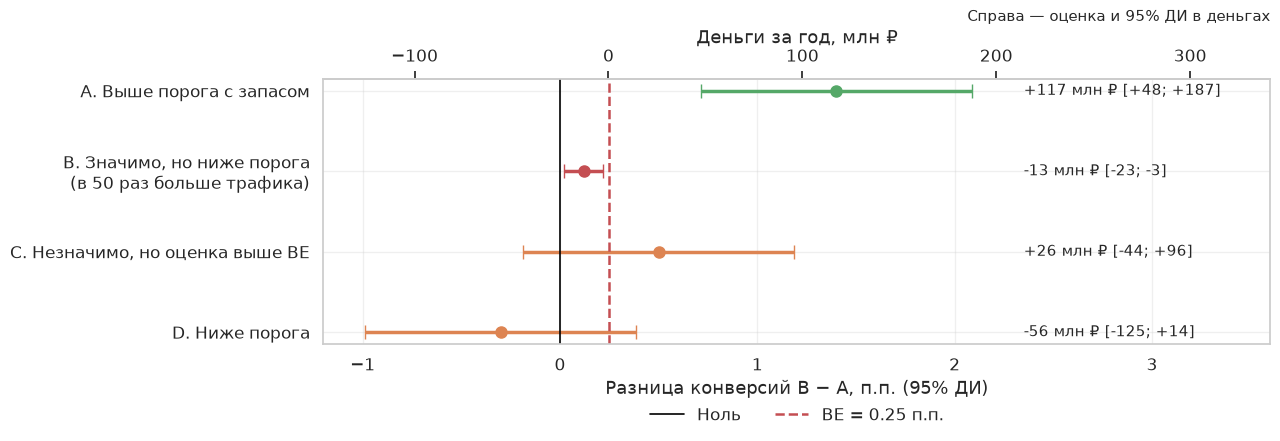

In [3]:
cases = [  # (подпись, оценка п.п., SE п.п.)
    ('A. Выше порога с запасом', 1.40, 0.35),
    ('B. Значимо, но ниже порога\n(в 50 раз больше трафика)', 0.12, 0.05),
    ('C. Незначимо, но оценка выше BE', 0.50, 0.35),
    ('D. Ниже порога', -0.30, 0.35),
]
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (label, est, se) in enumerate(cases):
    y = len(cases) - i
    lo, hi = est - 1.96 * se, est + 1.96 * se
    color = GREEN if lo > BE_PP else RED if hi < BE_PP else ORANGE
    ax.errorbar(est, y, xerr=1.96 * se, fmt='o', color=color, capsize=5, lw=2.5, ms=8)
    ax.text(2.35, y, f"{money(est):+.0f} млн ₽ [{money(lo):+.0f}; {money(hi):+.0f}]", va='center', fontsize=11)
ax.axvline(0, color='black', lw=1.2, label='Ноль')
ax.axvline(BE_PP, color=RED, ls='--', lw=1.8, label=f'BE = {BE_PP:.2f} п.п.')
ax.set_yticks(range(len(cases), 0, -1), [c[0] for c in cases])
ax.set_xlim(-1.2, 3.6)
ax.set_xlabel('Разница конверсий B − A, п.п. (95% ДИ)')
top = ax.secondary_xaxis('top', functions=(lambda d: money(d), lambda m: (m * 1e6 + TOTAL_COSTS) * 100 * P_A / (WEEKLY_REVENUE * HORIZON_WEEKS)))
top.set_xlabel('Деньги за год, млн ₽')
ax.set_title('Справа — оценка и 95% ДИ в деньгах', loc='right', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

* **A** — нижняя граница ДИ выше порога: внедрение выгодно с запасом. Так выглядит наш чекаут (раздел 2).
* **B** — классика «значимо = выгодно». При большом трафике ДИ узкий и отделён от нуля, но целиком ниже порога: внедрение убыточно.
* **C** — разберём в вопросе ниже.
* **D** — оценка ниже порога и даже ниже нуля. ДИ [−0.99; +0.39] накрывает и ноль, и BE, но по правилу решает оценка: не внедряем.

**Вопрос.** Исход **C**: против нуля незначимо, но оценка +0.50 п.п. выше порога 0.246. Внедряем или ждём значимости?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

По правилу встречи 1 — **внедряем**. Правило — одностороннее $\alpha = 0.5$ против BE, то есть «оценка выше порога». Модель встречи 1 выбрала его как максимум ожидаемой прибыли: ошибка по OEC стоит денег примерно линейно, а провал ловит мониторинг после раскатки.

«Ждать значимости» — значит поменять правило задним числом и потерять часть выгодных вариантов (сколько именно — в симуляции ниже).

Цену риска честно пишем в мемо: нижняя граница ДИ в деньгах — минус 44 млн ₽. Решение «внедряем» не отменяет того, что мы можем проиграть.

</details>

Насколько часто правило «значимо против нуля» ошибается в деньгах? Разыграем 200 тыс. тестов с ожиданиями встречи 1: истинный относительный эффект нормален со средним 0 и $\sigma = 1.5$%, то есть разница конверсий нормальна с $\sigma = 1.05$ п.п. Сравним два правила при нашем трафике и при стократном.

**Вопрос.** Трафика стало в 100 раз больше, ДИ сузился в 10 раз. Правило «значимо против нуля» от этого станет надёжнее в деньгах?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет — оно ошибается в другую сторону.

1. При $n_B$ = 21 тыс. правило «значимо против нуля» слишком строгое. Оно пропускает 36% выгодных вариантов и зарабатывает 26.5 млн ₽ на тест против 29.0 млн ₽ у правила «выше BE».
2. При стократном трафике то же правило внедряет невыгодные варианты: их 14% среди внедрённых против 1.3% у правила «выше BE».

Порог против нуля не знает, сколько стоит внедрение. Чем точнее тест, тем чаще «значимо» означает «значимо, но мелко» — исход B на графике выше.

</details>

In [4]:
rng = np.random.default_rng(6)
true_pp = rng.normal(0, 0.015 * P_A * 100, 200_000)
rows = []
for n_b in [21_000, 2_100_000]:
    se = 100 * np.sqrt(P_A * (1 - P_A) * (1 / (4 * n_b) + 1 / n_b))
    est = true_pp + rng.normal(0, se, true_pp.size)
    for rule, shipped in [('значимо против нуля (α = 0.05)', est > 1.96 * se), ('оценка выше BE (встреча 1)', est > BE_PP)]:
        rows.append({'n_B': f'{n_b:,}'.replace(',', ' '), 'SE, п.п.': f'{se:.3f}', 'Правило': rule,
                     'Внедряем, %': 100 * shipped.mean(),
                     'Невыгодных среди внедрённых, %': 100 * (true_pp[shipped] < BE_PP).mean(),
                     'Пропущено выгодных, %': 100 * (~shipped[true_pp > BE_PP]).mean(),
                     'Деньги на тест, млн ₽': (shipped * money(true_pp)).mean()})
pd.DataFrame(rows).set_index(['n_B', 'Правило']).round(1)

SE, п.п.  Внедряем, %  \
n_B       Правило                                                
21 000    значимо против нуля (α = 0.05)    0.354         26.5   
          оценка выше BE (встреча 1)        0.354         41.2   
2 100 000 значимо против нуля (α = 0.05)    0.035         47.3   
          оценка выше BE (встреча 1)        0.035         40.6   

                                          Невыгодных среди внедрённых, %  \
n_B       Правило                                                          
21 000    значимо против нуля (α = 0.05)                             2.5   
          оценка выше BE (встреча 1)                                13.1   
2 100 000 значимо против нуля (α = 0.05)                            14.1   
          оценка выше BE (встреча 1)                                 1.3   

                                          Пропущено выгодных, %  \
n_B       Правило                                                 
21 000    значимо против нуля (α = 0.05)                   36.3   
          оценка выше BE (встреча 1)                       11.8   
2 100 000 значимо против нуля (α = 0.05)                    0.0   
          оценка выше BE (встреча 1)                        1.4   

                                          Деньги на тест, млн ₽  
n_B       Правило                                                
21 000    значимо против нуля (α = 0.05)                   26.5  
          оценка выше BE (встреча 1)                       29.0  
2 100 000 значимо против нуля (α = 0.05)                   30.6  
          оценка выше BE (встреча 1)                       31.2

## 2. Эффект чекаута в метрике и в деньгах

### Данные и лестница решения

Повторяем очистку **как на встрече 3**: убираем полные дубли строк и целиком — пользователей, попавших в обе группы. Затем SRM: план — 80/20.

In [5]:
def clean_checkout(raw: pd.DataFrame) -> pd.DataFrame:
    """Очистка как на встрече 3: полные дубли строк, затем целиком — пользователи в обеих группах."""
    dedup = raw.drop_duplicates()
    n_groups = dedup.groupby('user_id')['group'].nunique()
    return dedup[~dedup['user_id'].isin(n_groups[n_groups > 1].index)].reset_index(drop=True)


raw = pd.read_csv(DATA / 'checkout_ab.csv')
df = clean_checkout(raw)

counts = df['group'].value_counts().reindex(['A', 'B'])
srm_p = chi2.sf(((counts - len(df) * np.array([0.8, 0.2])) ** 2 / (len(df) * np.array([0.8, 0.2]))).sum(), 1)
print(f"Строк: {spaced(len(raw))} → {spaced(len(df))}; A = {spaced(counts['A'])}, B = {spaced(counts['B'])}; SRM p = {srm_p:.3f}")
A, B = df[df['group'] == 'A'], df[df['group'] == 'B']

Строк: 105 330 → 104 960; A = 83 878, B = 21 082; SRM p = 0.487


Решение принимаем по лестнице:

| Шаг | Вопрос | Где считаем |
| --- | --- | --- |
| 1. Данные | Можно ли верить сравнению? (SRM, очистка) | раздел 2 |
| 2. Эффект | Насколько изменился OEC, 95% ДИ? | раздел 2 |
| 3. Деньги | Сколько это за горизонт, с ДИ? | раздел 2 |
| 4. Порог | Оценка выше BE (правило встречи 1)? | раздел 2 |
| 5. Guardrail | Доказано ли, что вред меньше границы? | раздел 4 |
| 6. Решение | внедряем / не внедряем как есть / не внедряем | раздел 4 → мемо |

Шаги 4 и 5 — оба необходимые условия. Провал любого из них останавливает внедрение, но по-разному. Провал шага 4 — «не внедряем». Провал шага 5 при пройденном шаге 4 — «не внедряем как есть».

### Эффект на конверсию и деньги

Разница средних, её SE (непулированная дисперсия) и двусторонний ДИ. Деньги считаем по наблюдаемой базе $\hat p_A$: относительный эффект $\delta / \hat p_A$ даёт ту же долю выручки. На плановой базе 0.70 1 п.п. стоит 101.8 млн ₽, на наблюдаемой — 102.0: на порог и решение это не влияет.

In [6]:
def diff_ci(x_a, x_b, level=0.95):
    """Разница средних B − A, её SE (непулированная) и двусторонний ДИ."""
    x_a, x_b = np.asarray(x_a, float), np.asarray(x_b, float)
    effect = x_b.mean() - x_a.mean()
    se = np.sqrt(x_a.var(ddof=1) / x_a.size + x_b.var(ddof=1) / x_b.size)
    z = norm.ppf(0.5 + level / 2)
    return {'effect': effect, 'se': se, 'ci': (effect - z * se, effect + z * se)}


p_a = A['converted'].mean()
conv = diff_ci(A['converted'], B['converted'])
effect_pp = 100 * conv['effect']
ci_pp = tuple(100 * np.array(conv['ci']))


def to_money(delta_pp):
    """п.п. конверсии → чистые ₽ за горизонт, по наблюдаемой базе."""
    return np.asarray(delta_pp) / (100 * p_a) * WEEKLY_REVENUE * HORIZON_WEEKS - TOTAL_COSTS


money_net = float(to_money(effect_pp))
money_ci = tuple(float(v) for v in to_money(ci_pp))
p_vs_zero = 2 * norm.sf(conv['effect'] / conv['se'])

print(f"Конверсия: A = {p_a:.2%}, B = {B['converted'].mean():.2%}; эффект {effect_pp:+.2f} п.п. "
      f"[{ci_pp[0]:+.2f}; {ci_pp[1]:+.2f}], относительный {effect_pp / (100 * p_a):+.2%}; p против нуля = {p_vs_zero:.1e}")
print(f"В деньгах за год (чистыми): {money_net / 1e6:+.1f} млн ₽ [{money_ci[0] / 1e6:+.1f}; {money_ci[1] / 1e6:+.1f}]")
print(f"При эффекте ровно BE: {float(to_money(BE_PP)) / 1e6:+.1f} млн ₽")

Конверсия: A = 69.87%, B = 71.26%; эффект +1.40 п.п. [+0.71; +2.08], относительный +2.00%; p против нуля = 6.4e-05
В деньгах за год (чистыми): +117.5 млн ₽ [+47.6; +187.4]
При эффекте ровно BE: +0.1 млн ₽


**Вопрос.** Что сказать владельцу продукта: «эффект значим» или «выше порога»? И деньги можно посчитать через конверсию, а можно напрямую через выручку на пользователя (ARPU). Что взять для мемо?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**«Выше порога»:**

* нижняя граница +0.71 п.п. почти втрое выше BE 0.25 п.п.;
* в деньгах +118 млн ₽ за год, ДИ от +48 до +187: окупается даже при худшем правдоподобном эффекте;
* p < 0.001 против нуля для решения ничего не добавляет.

**Через конверсию — с оговоркой:**

* Деньги через конверсию — модель с допущением: **средний чек не меняется**, выручка растёт пропорционально конверсии. Так считали точку безубыточности на встрече 1.
* В данных чек в B на 0.5% ниже, незначимо (раздел 3). Поэтому модель через конверсию немного оптимистична.
* Через ARPU точечная оценка ≈ +79 млн ₽ против +118 млн ₽ через конверсию. ДИ ARPU — примерно от −57 до +214 млн ₽, он накрывает ноль: выручка шумная, с тяжёлым хвостом. Решать по ней — значит почти всегда получать «непонятно».
* В мемо: оценка через конверсию, допущение — явно, ARPU-сверка — в «Рисках».

</details>

In [7]:
# Сверка через ARPU: ΔARPU × 52 500 пользователей в неделю × 52 недели − 25 млн ₽
arpu = diff_ci(A['revenue'], B['revenue'])
arpu_money = float(arpu['effect']) * WEEKLY_USERS * HORIZON_WEEKS - TOTAL_COSTS
arpu_money_ci = tuple(float(v) * WEEKLY_USERS * HORIZON_WEEKS - TOTAL_COSTS for v in arpu['ci'])
print(f"Через ARPU: Δ = {arpu['effect']:+.1f} ₽ [{arpu['ci'][0]:+.1f}; {arpu['ci'][1]:+.1f}] → "
      f"{arpu_money / 1e6:+.1f} млн ₽ [{arpu_money_ci[0] / 1e6:+.1f}; {arpu_money_ci[1] / 1e6:+.1f}]")

Через ARPU: Δ = +38.0 ₽ [-11.7; +87.6] → +78.6 млн ₽ [-56.8; +214.1]


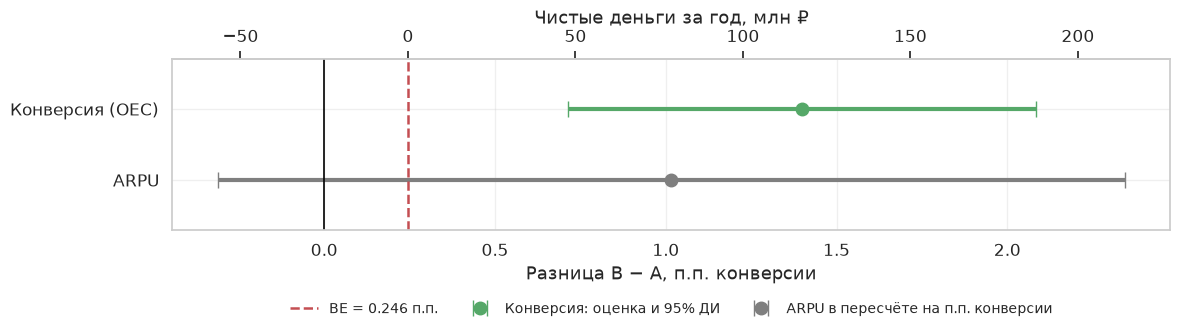

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.0))
ax.errorbar(effect_pp, 1, xerr=[[effect_pp - ci_pp[0]], [ci_pp[1] - effect_pp]], fmt='o', color=GREEN, capsize=6, lw=3, ms=9,
            label='Конверсия: оценка и 95% ДИ')
arpu_pp = [(m + TOTAL_COSTS) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a for m in arpu_money_ci]
ax.errorbar(np.mean(arpu_pp), 0, xerr=np.diff(arpu_pp) / 2, fmt='o', color=GRAY, capsize=6, lw=3, ms=9,
            label='ARPU в пересчёте на п.п. конверсии')
ax.axvline(0, color='black', lw=1.2)
ax.axvline(BE_PP, color=RED, ls='--', lw=1.8, label=f'BE = {BE_PP} п.п.')
ax.set_yticks([1, 0], ['Конверсия (OEC)', 'ARPU'])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel('Разница B − A, п.п. конверсии')
top = ax.secondary_xaxis('top', functions=(lambda d: to_money(d) / 1e6,
                                           lambda m: (np.asarray(m) * 1e6 + TOTAL_COSTS) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a))
top.set_xlabel('Чистые деньги за год, млн ₽')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=3, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

## 3. Ловушки интерпретации: ratio-метрики и парадокс Симпсона

Цифра в отчёте может быть верной, а вывод из неё — ложным. Две самые частые ловушки: ratio-метрика, у которой знаменатель зависит от варианта, и смешение групп с разными долями во времени (парадокс Симпсона). Третья — «значимо = выгодно» — уже разобрана в разделе 1.

### Ratio: средний чек на нашем чекауте

Средний чек = выручка / число заказов. Знаменатель — покупатели, а их состав меняет сам вариант.

**Вопрос.** Финансы замечают: средний чек в B ниже, чем в A. Это аргумент против внедрения? А если бы падение было значимым?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Средний чек в B упал на 0.5% (≈ 20 ₽, незначимо, p = 0.52), а выручка на пользователя выросла на 1.5%. Противоречия нет: ARPU = конверсия × чек, и 1.020 · 0.995 ≈ 1.015.

Новый чекаут довёл до заказа «маргинальных» покупателей — тех, кто раньше бросал корзину, — у них чек чуть ниже среднего. Сравнение чека — это сравнение **разных популяций**: покупатели A и покупатели B уже не рандомизированы. Поэтому даже значимое падение чека не было бы аргументом против.

Правила для ratio-метрик:

* решение принимаем по метрике **на пользователя** (единице рандомизации): ARPU, конверсия;
* чек, «выручка на заказ», CTR по показам — диагностика механизма («рост за счёт числа заказов, а не их размера»), а не критерий;
* у ratio-метрики свой SE: наблюдения в знаменателе зависимы, нужен дельта-метод или линеаризация (встреча 2), иначе SE занижен.

</details>

SE среднего чека считаем дельта-методом. Чек — отношение средних на пользователя, $r = \bar R / \bar C$ (выручка и факт заказа):

$$
\text{Var}(r) \approx \frac{\sigma_R^2 - 2 r \sigma_{RC} + r^2 \sigma_C^2}{n \bar C^2}
$$

In [9]:
table = df.groupby('group').agg(users=('user_id', 'size'), CR=('converted', 'mean'), ARPU=('revenue', 'mean'))
table['Средний чек'] = df[df['converted'] == 1].groupby('group')['revenue'].mean()
change = table.loc['B'] / table.loc['A'] - 1
print('Изменение B к A: ' + ', '.join(f"{name} {value:+.1%}" for name, value in change.drop('users').items()))


def ratio_mean_var(r, c):
    """Отношение средних и его дисперсия дельта-методом."""
    r, c = np.asarray(r, float), np.asarray(c, float)
    ratio = r.mean() / c.mean()
    cov = np.cov(r, c, ddof=1)
    var = (cov[0, 0] - 2 * ratio * cov[0, 1] + ratio ** 2 * cov[1, 1]) / (r.size * c.mean() ** 2)
    return ratio, var


aov_a, var_a = ratio_mean_var(A['revenue'], A['converted'])
aov_b, var_b = ratio_mean_var(B['revenue'], B['converted'])
aov_diff, aov_se = aov_b - aov_a, np.sqrt(var_a + var_b)
print(f"Средний чек: A = {spaced(aov_a)} ₽, B = {spaced(aov_b)} ₽; разница {aov_diff:+.0f} ₽ ± {1.96 * aov_se:.0f} "
      f"(p = {2 * norm.sf(abs(aov_diff / aov_se)):.2f})")
table.round(3)

Изменение B к A: CR +2.0%, ARPU +1.5%, Средний чек -0.5%
Средний чек: A = 3 728 ₽, B = 3 708 ₽; разница -20 ₽ ± 60 (p = 0.52)


,users,CR,ARPU,Средний чек
group,,,,
A,83878,0.699,2604.419,3727.684
B,21082,0.713,2642.374,3707.837


### Парадокс Симпсона: раскатка по шагам

Типичная ситуация: первую неделю вариант B получает 5% трафика (осторожный старт), вторую — 50%. Конверсия в первую неделю выше (распродажа). Внутри **каждой** недели B лучше A на 1 п.п.

**Вопрос.** Может ли B в сумме за две недели оказаться хуже A, если внутри каждой недели он лучше на 1 п.п.?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Может, и сильно. В сумме B «проигрывает» около 5 п.п. (−5.0 на графике ниже; по параметрам без шума — −4.6): почти весь его трафик пришёлся на неделю с низкой базой. Причина — доля B менялась во времени вместе с базовой конверсией.

Что делать:

* считать эффект **внутри страт** (дней, недель, шагов раскатки) и взвешивать по общему трафику страты — это стратифицированная оценка, она возвращает +1 п.п.;
* или анализировать только период с постоянным сплитом;
* SRM по дням — первый сигнал, что доли менялись (встреча 3).

Тот же механизм встречается в сегментах: если B чаще достаётся мобильным, а у мобильных ниже база, общий эффект врёт.

</details>

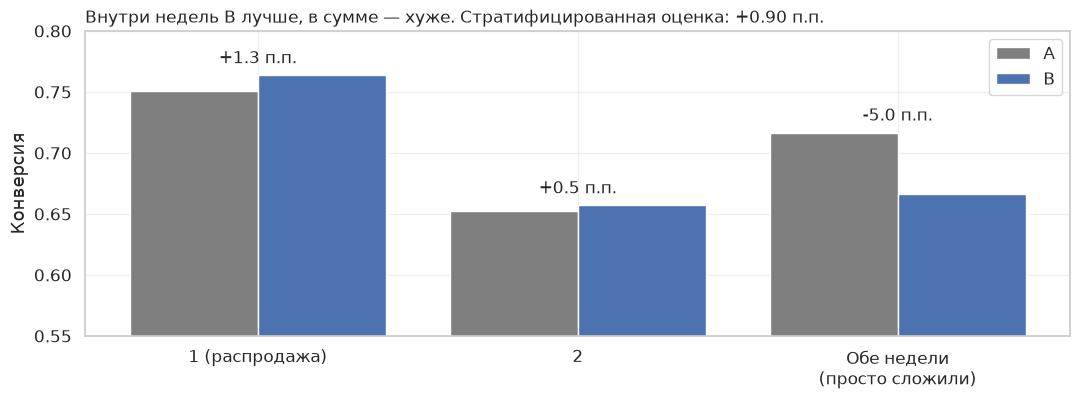

In [10]:
rng = np.random.default_rng(3)
weeks = pd.DataFrame({'Неделя': ['1 (распродажа)', '2'], 'users': [50_000, 50_000],
                      'share_b': [0.05, 0.50], 'cr_a': [0.75, 0.65]})
rows = []
for _, w in weeks.iterrows():
    for group, share, cr in [('A', 1 - w.share_b, w.cr_a), ('B', w.share_b, w.cr_a + 0.01)]:
        n = int(w.users * share)
        rows.append({'Неделя': w['Неделя'], 'group': group, 'n': n, 'orders': rng.binomial(n, cr)})
sim = pd.DataFrame(rows)
by_week = sim.pivot(index='Неделя', columns='group', values=['n', 'orders'])
cr_week = by_week['orders'] / by_week['n']
pooled = sim.groupby('group')[['n', 'orders']].sum()
cr_pooled = pooled['orders'] / pooled['n']
# Честная агрегация: разница внутри недели, взвешенная по общему трафику недели
weights = by_week['n'].sum(axis=1) / by_week['n'].values.sum()
stratified = ((cr_week['B'] - cr_week['A']) * weights).sum()

fig, ax = plt.subplots(figsize=(11, 4.2))
labels = list(cr_week.index) + ['Обе недели\n(просто сложили)']
xa = np.arange(3)
ax.bar(xa - 0.2, [*cr_week['A'], cr_pooled['A']], 0.4, color=GRAY, label='A')
ax.bar(xa + 0.2, [*cr_week['B'], cr_pooled['B']], 0.4, color=BLUE, label='B')
for x, a, b in zip(xa, [*cr_week['A'], cr_pooled['A']], [*cr_week['B'], cr_pooled['B']]):
    ax.text(x, max(a, b) + 0.01, f"{100 * (b - a):+.1f} п.п.", ha='center', fontsize=12)
ax.set_xticks(xa, labels)
ax.set_ylim(0.55, 0.8)
ax.set_ylabel('Конверсия')
ax.set_title(f'Внутри недель B лучше, в сумме — хуже. Стратифицированная оценка: {100 * stratified:+.2f} п.п.', loc='left', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Guardrail и решение по ролям метрик

Для метрики «не навредить» вопрос другой: доказано ли, что вред меньше допустимого? Нулевая гипотеза — «вред не меньше границы»:

$$
H_0: \delta \ge m
$$

Граница $m$ записана до запуска. Проходим, если односторонняя верхняя 95%-граница роста ниже $m$. Это проверка **non-inferiority**.

Роли и правило записаны до запуска, в дизайн-доке встречи 2:

| Метрика | Колонка | Роль | Проверка |
| --- | --- | --- | --- |
| Конверсия в заказ | `converted` | **OEC** | оценка выше BE = 0.246 п.п. (α = 0.5 против BE) |
| ARPU | `revenue` | вторичная | двусторонняя, поправка Холма внутри семейства вторичных |
| Время на чекауте | `checkout_time_sec` | вторичная | двусторонняя, поправка Холма внутри семейства вторичных |
| Ошибки оплаты | `payment_error` | **guardrail** | non-inferiority: рост не больше +0.2 п.п., одностороннее α = 0.05, без поправки |

**Правило:** внедряем, если данные надёжны (SRM в норме), OEC выше порога **и** guardrail доказал non-inferiority. Если OEC выше порога, а guardrail не прошёл — «не внедряем как есть»: это **правило эскалации из дизайн-дока встречи 2**. Иначе — «не внедряем».

**Вопрос.** Для OEC мы берём α = 0.5, а для guardrail — 0.05. Почему не одно и то же?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Потому что разные ошибки стоят по-разному.

* Ошибка по OEC стоит денег примерно линейно и ловится мониторингом после раскатки. Поэтому правило встречи 1 — $\alpha = 0.5$ против BE: это максимум ожидаемой прибыли.
* Вред по guardrail (сбои оплаты, отток, нагрузка на поддержку) плохо виден и плохо обратим. Поэтому бремя доказательства — на новом варианте, и $\alpha = 0.05$.

Поправку на множественность к guardrail не применяем: она ослабила бы защиту. Поправка у guardrail уходит в мощность при планировании (встреча 2), а Холм — только внутри семейства вторичных.

</details>

In [11]:
def non_inferiority(x_a, x_b, margin_pp, alpha=0.05):
    """Non-inferiority для метрики, где рост — плохо. H0: δ ≥ margin."""
    r = diff_ci(x_a, x_b)
    effect_pp, se_pp = 100 * r['effect'], 100 * r['se']
    upper_pp = effect_pp + norm.ppf(1 - alpha) * se_pp
    p_value = norm.cdf((effect_pp - margin_pp) / se_pp)     # малое p — доказали «рост меньше границы»
    return {'effect_pp': effect_pp, 'upper_pp': upper_pp, 'p_value': p_value, 'passed': upper_pp < margin_pp}


ROLES = {'converted': 'OEC', 'revenue': 'вторичная', 'checkout_time_sec': 'вторичная', 'payment_error': 'guardrail'}
rows = []
for col, role in ROLES.items():
    r = diff_ci(A[col], B[col])
    if role == 'OEC':
        p = norm.sf((100 * r['effect'] - BE_PP) / (100 * r['se']))       # H0: δ ≤ BE
    elif role == 'guardrail':
        p = non_inferiority(A[col], B[col], NI_MARGIN_PP)['p_value']     # H0: δ ≥ margin
    else:
        p = 2 * norm.sf(abs(r['effect'] / r['se']))
    rows.append({'metric': col, 'role': role, 'A': A[col].mean(), 'B': B[col].mean(), 'effect': r['effect'],
                 'ci_low': r['ci'][0], 'ci_high': r['ci'][1], 'p_value': p})
results = pd.DataFrame(rows).set_index('metric')
results['p_adj'] = results['p_value']
secondary = results['role'] == 'вторичная'
results.loc[secondary, 'p_adj'] = multipletests(results.loc[secondary, 'p_value'], method='holm')[1]
results.round(4)

,role,A,B,effect,ci_low,ci_high,p_value,p_adj
metric,,,,,,,,
converted,OEC,0.6987,0.7126,0.0140,0.0071,0.0208,0.0005,0.0005
revenue,вторичная,2604.4189,2642.3745,37.9556,-11.6615,87.5727,0.1338,0.1338
checkout_time_sec,вторичная,113.5294,110.3546,-3.1747,-4.2790,-2.0705,0.0000,0.0000
payment_error,guardrail,0.0200,0.0220,0.0020,-0.0002,0.0042,0.4930,0.4930


**Вопрос.** Коллега проверил ошибки оплаты «как обычно» — двусторонним тестом против нуля — и получил «незначимо». Значит, вреда нет и можно внедрять?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Незначимость — это отсутствие доказательств вреда, а не доказательство его отсутствия.

Двусторонний тест против нуля даёт p = 0.077 и «зелёный свет», хотя оценка роста ошибок +0.198 п.п. (≈ +0.20, +10%) почти на самой границе допустимого. Верхняя граница — +0.38 п.п., почти вдвое выше неё. Non-inferiority ставит бремя доказательства на новый вариант: он должен показать, что вред меньше границы. Здесь не показал.

Обратите внимание: точечная оценка +0.198 формально ниже допуска +0.2. Решает верхняя граница, а не точка.

</details>

In [12]:
guardrail = non_inferiority(A['payment_error'], B['payment_error'], NI_MARGIN_PP)
oec_passed = effect_pp > BE_PP
if srm_p > 0.001 and oec_passed and guardrail['passed']:
    DECISION = 'внедряем'
elif oec_passed:
    DECISION = 'не внедряем как есть'
else:
    DECISION = 'не внедряем'

r = diff_ci(A['payment_error'], B['payment_error'])
p_two = 2 * norm.sf(abs(r['effect'] / r['se']))
print(f"Двусторонний тест против нуля: p = {p_two:.3f} → «незначимо, вреда нет».")
print(f"Non-inferiority: верхняя граница +{guardrail['upper_pp']:.2f} п.п. > +{NI_MARGIN_PP} → безопасность не доказана.")
print(f"Guardrail: рост ошибок {guardrail['effect_pp']:+.3f} п.п. (≈ {guardrail['effect_pp']:+.2f}), верхняя граница {guardrail['upper_pp']:+.2f} п.п. "
      f"при границе +{NI_MARGIN_PP} → {'прошёл' if guardrail['passed'] else 'НЕ прошёл'} (p = {guardrail['p_value']:.2f})")
print('Решение:', DECISION)

Двусторонний тест против нуля: p = 0.077 → «незначимо, вреда нет».
Non-inferiority: верхняя граница +0.38 п.п. > +0.2 → безопасность не доказана.
Guardrail: рост ошибок +0.198 п.п. (≈ +0.20), верхняя граница +0.38 п.п. при границе +0.2 → НЕ прошёл (p = 0.49)
Решение: не внедряем как есть


Решение — **не внедряем как есть**. Конверсия растёт с запасом, поэтому вариант не выбрасываем: ищем причину ошибок оплаты (способ оплаты, платформа, банк) — это задача разработки, не статистики. После исправления — подтверждающий тест.

**Вопрос.** Каким должен быть подтверждающий тест? Почему не повторить тот же дизайн — 80/20 на две недели?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

По **правилу эскалации из дизайн-дока встречи 2** мощность закладываем **на guardrail**: 0.9, как в плане встречи 2. Нужно показать non-inferiority с границей 0.2 п.п. при истинной разнице 0, а значит:

$$
SE \le \frac{0.2}{1.645 + 1.28} = 0.068
$$

(в п.п.). Расчёт в ячейке ниже:

* **Сплит 50/50, а не 80/20.** Для non-inferiority нужна минимальная SE, а сбалансированный сплит её даёт. Риск для B ниже — баг починен.
* **Размер:** ≈ 84 тыс. пользователей на группу (≈ 168 тыс. всего), 23 дня трафика, в целых неделях — **4 недели**. На мощности 0.8 хватило бы 17 дней, но тогда guardrail снова стал бы самым слабым звеном решения — план встречи 2 именно это и запретил.
* **Правило решения записываем до старта:** внедряем, если верхняя граница ошибок оплаты < +0.2 п.п. и конверсия выше BE.
* **BE пересчитываем:** затраты первого теста (3 млн ₽) — невозвратные, стоимость фикса (допущение: 1 млн ₽) добавляется. Порог ≈ 0.23 п.п. вместо 0.246.
* **Цена ожидания:** каждая неделя без нового чекаута — около 2.7 млн ₽ недополученной выручки (2% от 137 млн ₽). Чинить быстро выгоднее, чем спорить о правиле.

Менять правило задним числом («конверсия же выросла») нельзя — это подгонка под результат.

</details>

In [13]:
FIX_COST = 1_000_000   # допущение: стоимость исправления оплаты; 3 млн ₽ первого теста — невозвратные
be_confirm_pp = (TOTAL_COSTS - COSTS['тест'] + FIX_COST) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a
print(f"BE подтверждающего теста: {be_confirm_pp:.3f} п.п. (было {BE_PP})")

# Подтверждающий тест: non-inferiority по ошибкам оплаты, мощность guardrail из плана встречи 2
CONFIRM_POWER, CONFIRM_SHARE_B = 0.9, 0.5
p_err_a = A['payment_error'].mean()
z_ni = norm.ppf(0.95) + norm.ppf(CONFIRM_POWER)
confirm_n = int(np.ceil(z_ni ** 2 * p_err_a * (1 - p_err_a) * (1 / CONFIRM_SHARE_B + 1 / (1 - CONFIRM_SHARE_B))
                        / (NI_MARGIN_PP / 100) ** 2))
confirm_days = int(np.ceil(confirm_n / (WEEKLY_USERS / 7)))
confirm_weeks = int(np.ceil(confirm_days / 7))
print(f"Подтверждающий тест 50/50, мощность {CONFIRM_POWER}: N = {spaced(confirm_n)} "
      f"({spaced(confirm_n / 2)} на группу), {confirm_days} дн. трафика → {confirm_weeks} нед.")

BE подтверждающего теста: 0.226 п.п. (было 0.246)
Подтверждающий тест 50/50, мощность 0.9: N = 167 699 (83 850 на группу), 23 дн. трафика → 4 нед.


In [14]:
# Для сравнения: та же схема на мощности 0.8
z_08 = norm.ppf(0.95) + norm.ppf(0.8)
n_08 = z_08 ** 2 * p_err_a * (1 - p_err_a) * (1 / CONFIRM_SHARE_B + 1 / (1 - CONFIRM_SHARE_B)) / (NI_MARGIN_PP / 100) ** 2
WEEK_COST_MLN = 0.02 * WEEKLY_REVENUE / 1e6     # недополученная выручка за неделю при эффекте +2%
print(f"Мощность 0.8: N = {spaced(n_08)}, {int(np.ceil(n_08 / (WEEKLY_USERS / 7)))} дн. трафика; "
      f"цена недели ожидания ≈ {WEEK_COST_MLN:.2f} млн ₽")

Мощность 0.8: N = 121 068, 17 дн. трафика; цена недели ожидания ≈ 2.74 млн ₽


### Связь со встречей 1

Встреча 1 спрашивала: стоит ли тестировать, если можно просто раскатить? Модель сказала «тестируем»: ожидаемая прибыль 26.0 млн ₽ против 2.75 млн ₽ при раскатке без теста. Теперь видно, откуда эта ценность.

* Без теста мы раскатили бы рост конверсии **вместе с ростом ошибок оплаты**, которого в конверсии не видно.
* Правило встречи 1 сработало: по OEC вариант выше порога, причём нижняя граница ДИ тоже выше BE, так что вывод по OEC не зависит от выбора α. Поэтому вариант не выбрасываем.
* Guardrail из плана встречи 2 сработал тоже: именно он превратил «выше порога» в «не внедряем как есть». Это не отменяет правило встречи 1, а добавляет второе необходимое условие.

Тест окупился не раскаткой, а тем, что нашёл, что чинить.

## 5. Сегменты без p-hacking

Каждый разрез — это ещё одна гипотеза. 10 разрезов по 2–4 значения — уже 30 сравнений. Без поправки хотя бы одно «выстрелит» с вероятностью около 80% (для независимых сравнений $1 - 0.95^{30}$ ≈ 79%).

Условный эффект в сегменте (CATE — conditional average treatment effect) оценивают так же, как средний эффект, но на подвыборке. Вопрос «отличается ли сегмент» — это тест **взаимодействия**: разница эффектов «сегмент против остальных», а не «эффект в сегменте против нуля».

### Симуляция: гетерогенности нет

Эффект одинаков во всех сегментах. Слева — вероятность найти хотя бы один «особый» сегмент при $K$ сравнениях. Справа — 20 сегментов с одинаковым эффектом +1 п.п.: оценка лучшего из них и та же оценка в подтверждающем тесте.

**Вопрос.** Из 20 сегментов с одинаковым истинным эффектом +1 п.п. выбрали тот, где оценка максимальна. Что он покажет в подтверждающем тесте?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Лучший из 20 одинаковых сегментов в среднем показывает +1.93 п.п. вместо +1. В подтверждающем тесте он возвращается к +1 п.п. Это регрессия к среднему (проклятие победителя), а не «эффект выдохся».

</details>

Лучший сегмент: средняя оценка +1.93 п.п., в подтверждающем тесте +1.00 п.п.


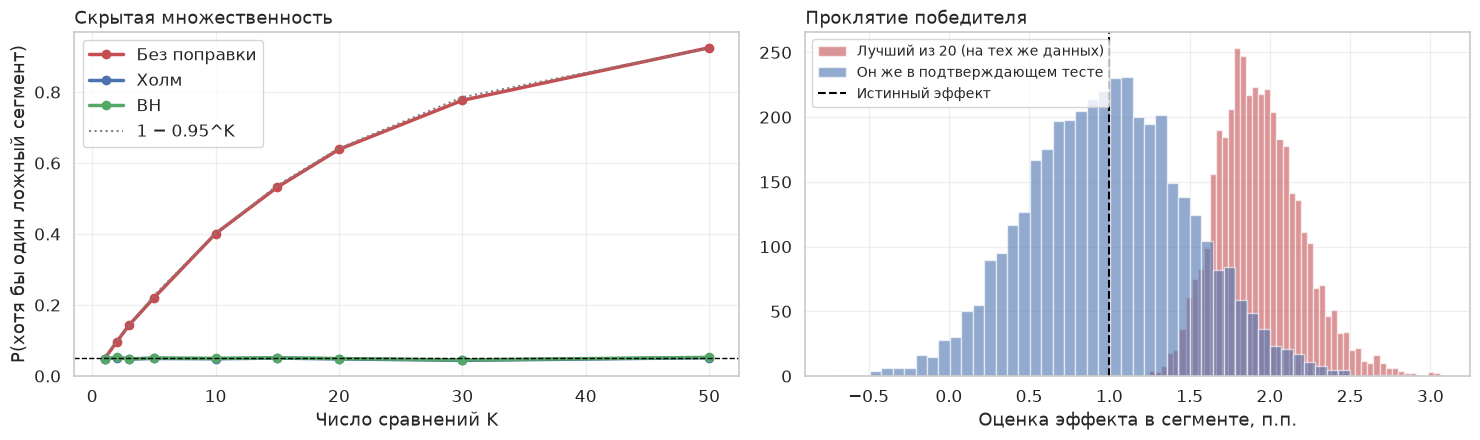

In [15]:
rng = np.random.default_rng(11)
K_grid = np.array([1, 2, 3, 5, 10, 15, 20, 30, 50])
reps = 4_000
fwer = {'Без поправки': [], 'Холм': [], 'BH': []}
for K in K_grid:
    p = np.sort(2 * norm.sf(np.abs(rng.normal(size=(reps, K)))), axis=1)
    fwer['Без поправки'].append((p[:, 0] < 0.05).mean())
    # Хоть одно отклонение: у Холма — если p_(1) < α/K, у BH — если p_(i) ≤ i·α/K хоть для одного i
    fwer['Холм'].append((p[:, 0] < 0.05 / K).mean())
    fwer['BH'].append((p <= 0.05 * np.arange(1, K + 1) / K).any(axis=1).mean())

# Проклятие победителя: 20 сегментов, у всех истинный эффект +1 п.п., SE в сегменте 0.5 п.п.
n_seg, true_effect, se_seg = 20, 1.0, 0.5
estimates = true_effect + rng.normal(0, se_seg, (reps, n_seg))
best = estimates.argmax(axis=1)
best_estimate = estimates[np.arange(reps), best]
confirm = true_effect + rng.normal(0, se_seg, reps)       # тот же сегмент в новом тесте
print(f"Лучший сегмент: средняя оценка {best_estimate.mean():+.2f} п.п., в подтверждающем тесте {confirm.mean():+.2f} п.п.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (name, values), color in zip(fwer.items(), [RED, BLUE, GREEN]):
    axes[0].plot(K_grid, values, 'o-', color=color, lw=2.5, label=name)
axes[0].plot(K_grid, 1 - 0.95 ** K_grid, ':', color=GRAY, label='1 − 0.95^K')
axes[0].axhline(0.05, color='black', ls='--', lw=1)
axes[0].set_xlabel('Число сравнений K')
axes[0].set_ylabel('P(хотя бы один ложный сегмент)')
axes[0].set_title('Скрытая множественность', loc='left')
axes[0].legend()
axes[1].hist(best_estimate, bins=50, color=RED, alpha=0.6, label='Лучший из 20 (на тех же данных)')
axes[1].hist(confirm, bins=50, color=BLUE, alpha=0.6, label='Он же в подтверждающем тесте')
axes[1].axvline(true_effect, color='black', ls='--', lw=1.5, label='Истинный эффект')
axes[1].set_xlabel('Оценка эффекта в сегменте, п.п.')
axes[1].set_title('Проклятие победителя', loc='left')
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

Слева: при 20 разрезах без поправки «особый» сегмент находится в 64% случаев ($1 - 0.95^{20}$), хотя его нет. Холм и BH держат 5%: когда гетерогенности нет совсем, BH контролирует ту же вероятность, что и Холм.

**Сколько сегментов можно смотреть.** Тест взаимодействия дорогой. Если сегмент — половина трафика, разница эффектов «сегмент против остальных» складывает две ошибки, и каждая из них в $\sqrt{2}$ раз больше общей:

$$
SE_{diff} = \sqrt{SE_1^2 + SE_2^2}
$$

$$
SE_{diff} = SE \cdot \sqrt{2 + 2} = 2 \cdot SE
$$

Чтобы увидеть разницу того же размера, что и общий эффект, нужно в 4 раза больше трафика. Для сегмента в 10% трафика — в 11 раз больше. Отсюда регламент:

1. **Преднамеченные** сегменты — 1–2, записаны в дизайн-доке до запуска, с гипотезой о механизме. По ним отчитываемся в мемо.
2. **Разведочные** — сколько угодно, но с поправкой (BH, если цель — список кандидатов; Холм, если ошибка дорогая) и с пометкой «гипотеза».
3. **Сегмент найден → подтверждающий тест** на этом сегменте. Таргетированную раскатку по разведочному сегменту без подтверждения не делаем.
4. Отчитываемся о числе просмотренных разрезов, а не только о «выстреливших».

Модели CATE (causal forest, meta-learners) — та же множественность в автоматическом режиме: сегмент ищет алгоритм. Правило то же: найденное проверяем на отложенных данных или в новом тесте.

### Кейс «Горящие предложения»

Данные встречи 4: 28 дней, сплит 50/50, метрика — `booked`. По условию кейса **преднамеченными** были два разреза: `device` и `is_new` — гипотеза, что блок сильнее помогает мобильным и новичкам. Остальное — разведка: `segment` (активность), `tenure` (корзины стажа) и пересечение `device × is_new`.

In [16]:
hd = pd.read_csv(DATA / 'hotdeals_segmented.csv')
SLICE_COLS = ['device', 'is_new', 'segment', 'tenure', 'device_new']
PREREGISTERED = ['device', 'is_new']
hd.head()

,user_id,date,group,booked,revenue,cancelled,device,reg_date,tenure_days,is_new,orders_90d,segment
0,100000,2026-09-07,B,0,0,0,mobile,2026-03-08,183,0,2,mid
1,100001,2026-09-07,A,0,0,0,mobile,2026-08-27,11,1,1,low
2,100002,2026-09-07,B,0,0,0,web,2026-05-30,100,0,4,mid
3,100003,2026-09-07,A,0,0,0,mobile,2025-06-24,440,0,5,high
4,100004,2026-09-07,A,0,0,0,mobile,2025-09-08,364,0,4,mid


Функция `slice_effects` возвращает по значениям разреза: `n`, `effect_pp` и `se_pp` (эффект в сегменте), `p` (против нуля), `diff_pp` и `p_het` (разница эффекта «сегмент − остальные» и её двусторонний p — тест взаимодействия).

15 строк — это не 15 независимых гипотез: у бинарного разреза обе строки дают один и тот же `p_het`, а `tenure 0–30` совпадает с `is_new = new`. Поэтому поправка по 15 строкам консервативная.

In [17]:
hd['is_new'] = np.where(hd['is_new'] == 1, 'new', 'old')
hd['tenure'] = pd.cut(hd['tenure_days'], [-1, 30, 180, 365, 730], labels=['0–30', '31–180', '181–365', '366–730']).astype(str)
hd['device_new'] = hd['device'] + '/' + hd['is_new']


def slice_effects(data, col):
    """Эффект в каждом значении разреза и тест взаимодействия «сегмент против остальных»."""
    rows = []
    for value in sorted(data[col].unique()):
        inside = data[col] == value
        seg = data[inside]
        rest = data[~inside]
        e_in = diff_ci(seg.loc[seg['group'] == 'A', 'booked'], seg.loc[seg['group'] == 'B', 'booked'])
        e_out = diff_ci(rest.loc[rest['group'] == 'A', 'booked'], rest.loc[rest['group'] == 'B', 'booked'])
        diff, se_diff = e_in['effect'] - e_out['effect'], np.hypot(e_in['se'], e_out['se'])
        rows.append({'slice': col, 'value': value, 'n': int(inside.sum()),
                     'effect_pp': 100 * e_in['effect'], 'se_pp': 100 * e_in['se'],
                     'p': 2 * norm.sf(abs(e_in['effect'] / e_in['se'])),
                     'diff_pp': 100 * diff, 'p_het': 2 * norm.sf(abs(diff / se_diff))})
    return pd.DataFrame(rows)

In [18]:
slices = pd.concat([slice_effects(hd, col) for col in SLICE_COLS], ignore_index=True)
for column in ['p', 'p_het']:
    slices[column + '_holm'] = multipletests(slices[column], method='holm')[1]
    slices[column + '_bh'] = multipletests(slices[column], method='fdr_bh')[1]
n_sig_raw, n_sig_holm, n_sig_bh = [(slices[c] < 0.05).sum() for c in ['p', 'p_holm', 'p_bh']]
n_het_raw, n_het_holm = [(slices[c] < 0.05).sum() for c in ['p_het', 'p_het_holm']]

total = diff_ci(hd.loc[hd['group'] == 'A', 'booked'], hd.loc[hd['group'] == 'B', 'booked'])
print(f"Общий эффект: {100 * total['effect']:+.2f} п.п. (p = {2 * norm.sf(total['effect'] / total['se']):.1e})")
print(f"Значимы против нуля: без поправки {n_sig_raw} из 15, Холм {n_sig_holm}, BH {n_sig_bh}")
print(f"Отличаются от остальных (взаимодействие): без поправки {n_het_raw}, Холм {n_het_holm}")
slices.round(3)

Общий эффект: +0.35 п.п. (p = 1.0e-03)
Значимы против нуля: без поправки 8 из 15, Холм 2, BH 5
Отличаются от остальных (взаимодействие): без поправки 2, Холм 1


,slice,value,n,effect_pp,se_pp,p,diff_pp,p_het,p_holm,p_bh,p_het_holm,p_het_bh
0,device,mobile,92423,0.525,0.140,0.000,0.389,0.070,0.003,0.001,0.909,0.262
1,device,web,75735,0.136,0.163,0.403,-0.389,0.070,1.000,0.504,0.909,0.262
2,is_new,new,50759,0.563,0.197,0.004,0.306,0.190,0.055,0.016,1.000,0.356
3,is_new,old,117399,0.257,0.126,0.042,-0.306,0.190,0.382,0.080,1.000,0.356
4,segment,high,26158,0.145,0.264,0.583,-0.243,0.399,1.000,0.672,1.000,0.599
5,segment,low,61254,0.400,0.177,0.024,0.079,0.721,0.240,0.060,1.000,0.772
6,segment,mid,80746,0.379,0.154,0.014,0.056,0.791,0.152,0.042,1.000,0.791
7,tenure,0–30,50759,0.563,0.197,0.004,0.306,0.190,0.055,0.016,1.000,0.356
8,tenure,181–365,30899,0.494,0.244,0.043,0.177,0.513,0.382,0.080,1.000,0.700
9,tenure,31–180,25341,0.451,0.271,0.096,0.120,0.683,0.577,0.144,1.000,0.772


A/A-проверка: 300 раз перемешаем метки групп. Эффекта нет ни в одном сегменте — сколько из 15 всё равно «выстрелит» против нуля при 5%?

In [19]:
rng = np.random.default_rng(6)
masks = np.array([(hd[col] == value).to_numpy() for col, value in zip(slices['slice'], slices['value'])], dtype=float)
y = hd['booked'].to_numpy(float)
is_b = (hd['group'] == 'B').to_numpy(float)
aa_counts = []
for _ in range(300):
    b = rng.permutation(is_b)
    n_b, n_all = masks @ b, masks.sum(axis=1)
    s_b, s_all = masks @ (y * b), masks @ y
    p_b, p_a_ = s_b / n_b, (s_all - s_b) / (n_all - n_b)
    se = np.sqrt(p_b * (1 - p_b) / n_b + p_a_ * (1 - p_a_) / (n_all - n_b))
    aa_counts.append(int((2 * norm.sf(np.abs(p_b - p_a_) / se) < 0.05).sum()))
aa_counts = np.array(aa_counts)
print(f"A/A: в среднем выстреливает {aa_counts.mean():.2f} сегмента, хотя бы один — в {np.mean(aa_counts >= 1):.0%} прогонов")

A/A: в среднем выстреливает 0.68 сегмента, хотя бы один — в 35% прогонов


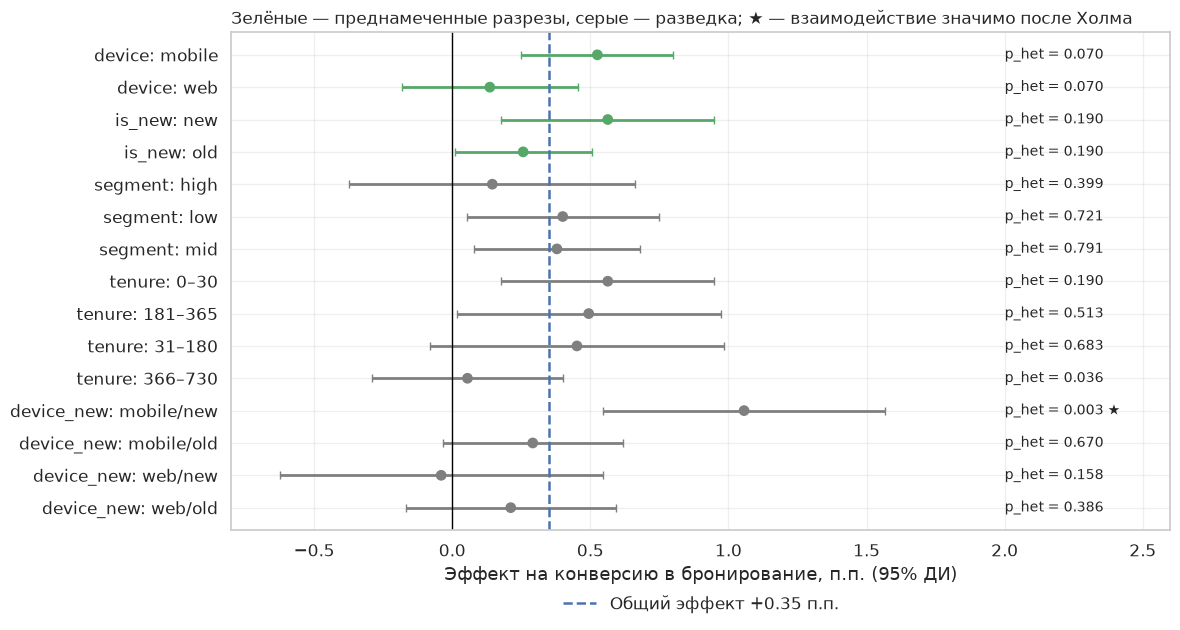

In [20]:
fig, ax = plt.subplots(figsize=(12, 6.5))
order = slices.iloc[::-1].reset_index(drop=True)
colors = [GREEN if s in PREREGISTERED else GRAY for s in order['slice']]
for i, row in order.iterrows():
    ax.errorbar(row['effect_pp'], i, xerr=1.96 * row['se_pp'], fmt='none', ecolor=colors[i], capsize=3, lw=2)
ax.scatter(order['effect_pp'], order.index, c=colors, s=45, zorder=3)
ax.axvline(0, color='black', lw=1)
ax.axvline(100 * total['effect'], color=BLUE, ls='--', lw=1.8, label=f"Общий эффект {100 * total['effect']:+.2f} п.п.")
for i, row in order.iterrows():
    mark = ' ★' if row['p_het_holm'] < 0.05 else ''
    ax.text(2.0, i, f"p_het = {row['p_het']:.3f}{mark}", va='center', fontsize=10)
ax.set_yticks(order.index, [f"{s}: {v}" for s, v in zip(order['slice'], order['value'])])
ax.set_xlim(-0.8, 2.6)
ax.set_xlabel('Эффект на конверсию в бронирование, п.п. (95% ДИ)')
ax.set_title('Зелёные — преднамеченные разрезы, серые — разведка; ★ — взаимодействие значимо после Холма', loc='left', fontsize=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

**Вопрос.** Продакт пишет: «В 8 сегментах из 15 значимо! Особенно low и mid». Что вы отвечаете и что попадает в отчёт?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. **«Значимо против нуля» — не тот вопрос.** Общий эффект +0.35 п.п. значим. Поэтому в любом крупном сегменте эффект тоже «значим»: там тот же средний эффект. Сегмент интересен, только если он **отличается от остальных**. Это тест взаимодействия (`p_het`). У low и mid `p_het` = 0.72 и 0.79 — ничем не отличаются.
2. **Скрытая множественность.** При перемешанных метках хотя бы один из 15 сегментов «выстреливает» примерно в трети прогонов. 8 «значимых» без поправки — в основном эхо общего эффекта. После Холма против нуля остаются 2 (mobile и mobile/new).
3. **Преднамеченные разрезы** (device, is_new): точечные оценки различаются — мобильные +0.53 против +0.14 п.п. у веба, новички +0.56 против +0.26 п.п. Но взаимодействие незначимо (`p_het` = 0.07 и 0.19). Тест не рассчитывали на сегменты, а SE разницы вдвое больше SE общего эффекта. В отчёт: «направление согласуется с гипотезой, мощности не хватило».
4. **Разведка.** Единственный разрез, переживший Холма по взаимодействию, — mobile/new: +1.06 п.п. против +0.21 у остальных, `p_het` = 0.003, после Холма — 0.045, на самой границе: при чуть другом числе разрезов он бы не прошёл. Это **гипотеза** для подтверждающего теста на мобильных новичках, а не основание для таргетированной раскатки. Лучший из 15 сегментов к тому же переоценён (проклятие победителя).
5. **Замечание о данных:** `tenure 0–30` — это ровно `is_new = new`. Одни и те же пользователи под двумя именами — тоже скрытая множественность.
6. Все оценки — средние за 28 дней. Во встрече 4 когортный анализ показал, что поздние когорты слабее ранних, поэтому и средний, и сегментные эффекты, скорее всего, завышают долгосрочный.

</details>

### Проверка на отложенной половине

Дешёвая проверка разведки: делим пользователей пополам по чётности `user_id`, ищем лучший разрез по `p_het` на первой половине и смотрим тот же разрез на второй.

In [21]:
half_1, half_2 = hd[hd['user_id'] % 2 == 0], hd[hd['user_id'] % 2 == 1]
explore = pd.concat([slice_effects(half_1, col) for col in SLICE_COLS], ignore_index=True)
best = explore.loc[explore['p_het'].idxmin()]
best_slice = (best['slice'], best['value'])
found_diff = best['diff_pp']
check = slice_effects(half_2, best['slice']).set_index('value').loc[best['value']]
check_diff, check_p_het = check['diff_pp'], check['p_het']
print(f"Разведка: {best_slice} разница {found_diff:+.2f} п.п., p_het = {best['p_het']:.4f}")
print(f"Проверка: разница {check_diff:+.2f} п.п., p_het = {check_p_het:.3f}")

Разведка: ('device_new', 'mobile/new') разница +0.97 п.п., p_het = 0.0155
Проверка: разница +0.73 п.п., p_het = 0.074


Лучший разрез на половине данных почти всегда переоценён: его выбрали именно потому, что шум сложился в его пользу. На второй половине разница меньше: +0.73 п.п. вместо +0.97. Если сегмент реальный, разница на второй половине остаётся положительной; если нет — стремится к нулю. Здесь направление сохранилось, но одной половины данных для вывода мало.

Отложенная половина — дешёвая замена подтверждающего теста. Но она вдвое уменьшает мощность и разведки, и проверки: на второй половине `p_het` = 0.074, «не прошёл». Поэтому для решения о таргетированной раскатке нужен отдельный тест.

## 6. Портфель и ревью-борд

Один тест — шумная оценка. Портфель тестов — данные о том, какие эффекты у нас вообще бывают. Мета-анализ объединяет тесты и отвечает на два вопроса: каков средний эффект и насколько тесты различаются.

**Fixed effects.** Все тесты оценивают один эффект, веса $w_i = 1 / SE_i^2$:

$$
\hat\mu_{FE} = \frac{\sum w_i \hat\theta_i}{\sum w_i}
$$

**Неоднородность.** При однородности статистика $Q$ распределена как хи-квадрат с $k - 1$ степенями свободы:

$$
Q = \sum w_i (\hat\theta_i - \hat\mu_{FE})^2
$$

$$
I^2 = \max\left(0, \frac{Q - (k - 1)}{Q}\right)
$$

$I^2$ — доля разброса, которую не объясняет шум: 25% — низкая, 50% — умеренная, 75% — высокая.

**Random effects** (DerSimonian–Laird). Истинные эффекты тестов сами разбросаны: $\theta_i \sim N(\mu, \tau^2)$. Оценка разброса:

$$
\hat\tau^2 = \max\left(0, \frac{Q - (k - 1)}{\sum w_i - \sum w_i^2 / \sum w_i}\right)
$$

Веса становятся $1 / (SE_i^2 + \hat\tau^2)$.

**Shrinkage** (эмпирический Байес). Оценка теста сжимается к среднему портфеля, шумные тесты — сильнее:

$$
\tilde\theta_i = \hat\mu + B_i (\hat\theta_i - \hat\mu)
$$

$$
B_i = \frac{\tau^2}{\tau^2 + SE_i^2}
$$

Сжимаем только к среднему **сравнимых** тестов. Если в портфеле есть выброс другого класса, его не сжимают к общему среднему, а разбирают отдельно.

### Симуляция

10 тестов, истинные эффекты нормальны со средним 0.2 п.п. и $\tau = 0.15$ п.п., SE от 0.08 до 0.25 п.п. Сначала один портфель на forest plot, затем 2 000 портфелей: покрытие среднего и ошибка оценок отдельных тестов.

**Вопрос.** Тесты в портфеле действительно разные. Чей 95% ДИ для среднего эффекта честнее — fixed или random effects? И зачем сжимать оценки отдельных тестов?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Random effects.** Когда тесты разные ($\tau > 0$), ДИ fixed effects слишком узкий: в симуляции он накрывает истинное среднее в 79% случаев вместо 95%. Random effects — 92%. При малом $k$ даже DL немного не дотягивает — для отчёта есть поправка Хартунга–Кнаппа.
* **Shrinkage** уменьшает ошибку оценок отдельных тестов: RMSE падает с 0.171 до 0.122 п.п. Для портфеля с разбросом эффектов это лучше, чем верить каждой оценке как есть. Сжатые оценки — честная база для ожиданий следующего теста (вход встречи 1) и для «сколько мы заработали за квартал».
* **$I^2$ — не тест, а описание.** Высокий $I^2$ говорит «не усредняйте вслепую»: ищите тест-выброс и причину различий.

</details>

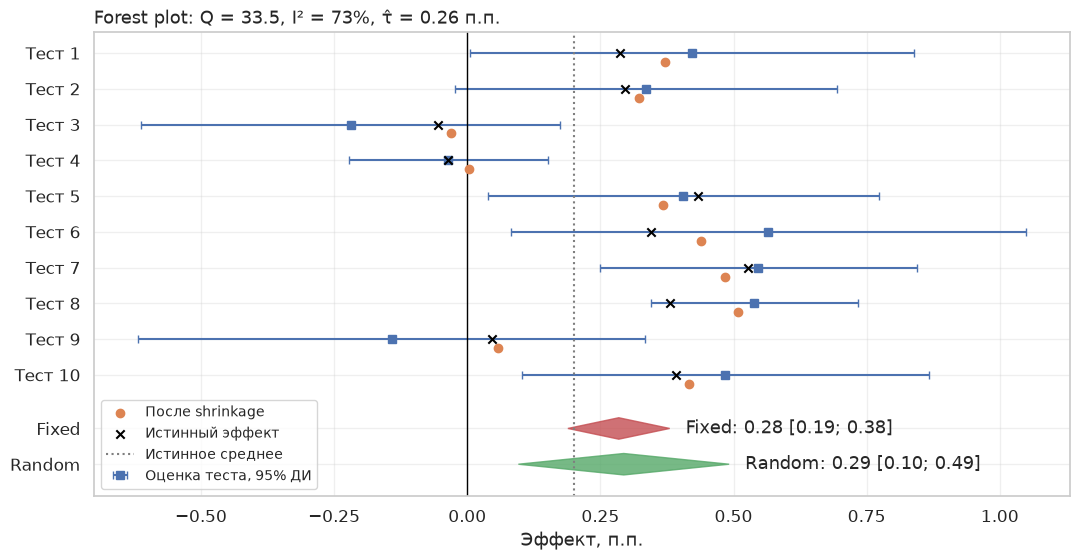

Покрытие среднего 95% ДИ: fixed 79%, random 92%
Средняя ошибка оценки теста (RMSE): исходная 0.171 п.п., после shrinkage 0.122 п.п.


In [22]:
def meta(effect, se):
    """Fixed и random effects (DerSimonian–Laird) для эффектов и их SE."""
    effect, se = np.asarray(effect, float), np.asarray(se, float)
    w = 1 / se ** 2
    fe = np.sum(w * effect) / w.sum()
    q = np.sum(w * (effect - fe) ** 2)
    k = effect.size
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    w_re = 1 / (se ** 2 + tau2)
    re = np.sum(w_re * effect) / w_re.sum()
    return {'fe': fe, 'se_fe': 1 / np.sqrt(w.sum()), 'q': q, 'i2': max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0,
            'tau2': tau2, 're': re, 'se_re': 1 / np.sqrt(w_re.sum()),
            'shrunk': re + tau2 / (tau2 + se ** 2) * (effect - re)}


rng = np.random.default_rng(21)
k, mu, tau = 10, 0.2, 0.15


def portfolio():
    se = rng.uniform(0.08, 0.25, k)
    theta = rng.normal(mu, tau, k)
    return theta, theta + rng.normal(0, se), se


theta, est, se = portfolio()
m = meta(est, se)
fig, ax = plt.subplots(figsize=(11, 5.8))
rows = np.arange(k)[::-1] + 3
ax.errorbar(est, rows, xerr=1.96 * se, fmt='s', color=BLUE, capsize=3, label='Оценка теста, 95% ДИ')
ax.scatter(m['shrunk'], rows - 0.25, color=ORANGE, zorder=3, label='После shrinkage')
ax.scatter(theta, rows, marker='x', color='black', zorder=4, label='Истинный эффект')
for y, centre, half, color, name in [(1.5, m['fe'], 1.96 * m['se_fe'], RED, 'Fixed'), (0.5, m['re'], 1.96 * m['se_re'], GREEN, 'Random')]:
    ax.fill([centre - half, centre, centre + half, centre], [y, y + 0.3, y, y - 0.3], color=color, alpha=0.8)
    ax.text(centre + half + 0.03, y, f"{name}: {centre:.2f} [{centre - half:.2f}; {centre + half:.2f}]", va='center')
ax.axvline(0, color='black', lw=1)
ax.axvline(mu, color=GRAY, ls=':', lw=1.5, label='Истинное среднее')
ax.set_yticks([*rows, 1.5, 0.5], [f'Тест {i + 1}' for i in range(k)] + ['Fixed', 'Random'])
ax.set_xlabel('Эффект, п.п.')
ax.set_title(f"Forest plot: Q = {m['q']:.1f}, I² = {m['i2']:.0%}, τ̂ = {np.sqrt(m['tau2']):.2f} п.п.", loc='left')
ax.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

cover = {'Fixed': 0, 'Random': 0}
mse_raw = mse_shrunk = 0.0
for _ in range(2_000):
    theta, est, se = portfolio()
    m = meta(est, se)
    cover['Fixed'] += abs(m['fe'] - mu) < 1.96 * m['se_fe']
    cover['Random'] += abs(m['re'] - mu) < 1.96 * m['se_re']
    mse_raw += np.mean((est - theta) ** 2) / 2_000
    mse_shrunk += np.mean((m['shrunk'] - theta) ** 2) / 2_000
print(f"Покрытие среднего 95% ДИ: fixed {cover['Fixed'] / 2_000:.0%}, random {cover['Random'] / 2_000:.0%}")
print(f"Средняя ошибка оценки теста (RMSE): исходная {np.sqrt(mse_raw):.3f} п.п., после shrinkage {np.sqrt(mse_shrunk):.3f} п.п.")

### Портфель квартала

Шесть тестов квартала, эффект и SE — в п.п. конверсии. Это тесты другого продукта — маркетплейса с базой конверсии около 5%. CHK-203 — его чекаут, не наш сквозной кейс. Базы конверсии у тестов близки (4.7–5.2%), поэтому эффекты в п.п. сравнимы. При сильно разных базах объединяют относительные эффекты — эффект, делённый на базу.

У каждого теста своя точка безубыточности из его плана.

In [23]:
portfolio = pd.read_csv(DATA / 'portfolio_tests.csv')
# Точки безубыточности из планов тестов (условие кейса): у каждого продукта свои затраты и выручка
BE_BY_TEST = {'HD-101': 0.15, 'PRM-104': 0.22, 'CHK-203': 0.25, 'PUSH-307': 0.10, 'ONB-112': 0.40, 'FILT-408': 0.10}
portfolio['break_even_pp'] = portfolio['test_id'].map(BE_BY_TEST)
portfolio[['test_id', 'name', 'n', 'base_rate', 'effect', 'se', 'ci_low', 'ci_high', 'p_value', 'break_even_pp']]

,test_id,name,n,base_rate,effect,se,ci_low,ci_high,p_value,break_even_pp
0,HD-101,Блок рекомендаций на главной,52000,0.050,0.334,0.135,0.069,0.599,0.0135,0.15
1,PRM-104,Промо-баннер в выдаче,38000,0.048,0.276,0.155,-0.028,0.580,0.0751,0.22
2,CHK-203,Новый чекаут v2,78000,0.052,0.187,0.112,-0.033,0.408,0.0954,0.25
3,PUSH-307,Другое время push-рассылки,64000,0.050,0.063,0.122,-0.176,0.302,0.6064,0.10
4,ONB-112,Мобильный онбординг,30000,0.047,1.210,0.173,0.871,1.549,0.0000,0.40
5,FILT-408,Фильтр по цене в поиске,44000,0.051,-0.227,0.148,-0.518,0.064,0.1257,0.10


Считаем мета-анализ по всем шести тестам, ищем выброс через leave-one-out (тест, без которого $I^2$ падает сильнее всего) и считаем две доли «здоровья процесса»: прошедшие своё правило (оценка выше BE своего теста) и значимые выигрыши (p < 0.05 и эффект больше нуля — так считают в отрасли). Выброс к среднему остальных не сжимаем: это другой класс изменений.

**Вопрос.** Что сказать ревью-борду: каков «средний эффект теста», какой тест выбивается из портфеля, о чём говорит результат PUSH-307 и нормально ли, что доля тестов, прошедших своё правило, выше доли значимых выигрышей?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Все шесть усреднять нельзя.** $Q$ = 44 при 5 степенях свободы, $I^2$ = 89%: почти весь разброс — не шум.
* Fixed effects даёт +0.25 ± 0.11 п.п., но эта точность ложная. Random effects честнее: +0.30 ± 0.33 п.п., ДИ задевает ноль. Чего ждать от нового теста — интервал предсказания (с t-квантилем, 4 степени свободы): от −0.9 до +1.5 п.п.
* **Гетерогенный тест — ONB-112** (мобильный онбординг, +1.21 п.п.). Без него $I^2$ = 58%, среднее RE +0.13 п.п. Это другой класс изменений (новый сценарий, а не правка экрана). Его не выбрасываем и не сжимаем к чужому среднему: в отчёте он идёт отдельной строкой.
* **PUSH-307 — нулевой, и это результат.** Оценка +0.06 п.п., ДИ от −0.18 до +0.30: эффект больше 0.3 п.п. маловероятен. Время рассылки — слабый рычаг. После shrinkage +0.09: шумный тест подтягивается к среднему.
* **FILT-408** (−0.23 п.п., p = 0.13) похож на вред и после shrinkage остаётся отрицательным (−0.06). Не внедряем.
* **Две доли — это нормально.** Своё правило (оценка выше BE) прошли 3 из 6: HD-101, PRM-104, ONB-112. Значимых выигрышей 2 из 6, около трети, как в отрасли. Разница ожидаема: при α = 0.5 против BE мы сознательно внедряем больше.
* **Сжатые оценки нужны для победителей.** Среднее пяти тестов shrinkage почти не меняет (+0.127 → +0.129). Зато внедрённые HD-101 и PRM-104 сжимаются в среднем с +0.31 до +0.22 п.п. У PRM-104 сжатая оценка +0.20 уже ниже его BE 0.22: на ожидания квартала её не закладываем. Ожидания следующего квартала — по сжатым оценкам и RE без выброса (+0.13 п.п.), онбординг — отдельно.

</details>

In [24]:
# meta() — та же функция, что в симуляции выше
meta_all = meta(portfolio['effect'], portfolio['se'])
loo = {row.test_id: meta(portfolio.loc[portfolio.index != i, 'effect'], portfolio.loc[portfolio.index != i, 'se'])['i2']
       for i, row in portfolio.iterrows()}
outlier = min(loo, key=loo.get)
rest = portfolio[portfolio['test_id'] != outlier]
meta_wo = meta(rest['effect'], rest['se'])

ship_rate = (portfolio['effect'] > portfolio['break_even_pp']).mean()
sig_win_rate = ((portfolio['p_value'] < 0.05) & (portfolio['effect'] > 0)).mean()

# Shrinkage к RE пяти сравнимых тестов; выброс не сжимаем
is_outlier = portfolio['test_id'] == outlier
weight = meta_wo['tau2'] / (meta_wo['tau2'] + portfolio['se'] ** 2)
portfolio['shrunk'] = np.where(is_outlier, portfolio['effect'],
                               meta_wo['re'] + weight * (portfolio['effect'] - meta_wo['re']))
ship_shrunk = portfolio['shrunk'] > portfolio['break_even_pp']

for name, m in [('Все 6', meta_all), (f'Без {outlier}', meta_wo)]:
    print(f"{name}: FE {m['fe']:+.3f} ± {1.96 * m['se_fe']:.3f}, RE {m['re']:+.3f} ± {1.96 * m['se_re']:.3f} п.п.; "
          f"Q = {m['q']:.1f} (p = {chi2.sf(m['q'], 5 if name == 'Все 6' else 4):.1e}), I² = {m['i2']:.0%}, τ = {np.sqrt(m['tau2']):.3f}")
k_all = len(portfolio)
pi_half = student_t.ppf(0.975, k_all - 2) * np.sqrt(meta_all['tau2'] + meta_all['se_re'] ** 2)
print(f"Интервал предсказания для нового теста (t, {k_all - 2} ст. св.): [{meta_all['re'] - pi_half:+.2f}; {meta_all['re'] + pi_half:+.2f}] п.п.")
print(f"Leave-one-out I²: " + ', '.join(f"{k} {v:.0%}" for k, v in loo.items()))
print(f"Прошли своё правило (оценка > BE): {ship_rate:.0%}; значимых выигрышей: {sig_win_rate:.0%}; по сжатым оценкам выше BE: {ship_shrunk.mean():.0%}")
print(f"Без {outlier}: средний эффект сырой {rest['effect'].mean():+.3f}, после shrinkage {portfolio.loc[~is_outlier, 'shrunk'].mean():+.3f} п.п.; "
      f"{outlier} — отдельно: {portfolio.loc[is_outlier, 'effect'].item():+.2f} п.п.")
portfolio[['test_id', 'effect', 'se', 'p_value', 'break_even_pp', 'shrunk']].round(3)

Все 6: FE +0.245 ± 0.109, RE +0.298 ± 0.329 п.п.; Q = 44.3 (p = 2.1e-08), I² = 89%, τ = 0.386
Без ONB-112: FE +0.134 ± 0.115, RE +0.129 ± 0.180 п.п.; Q = 9.5 (p = 4.9e-02), I² = 58%, τ = 0.156
Интервал предсказания для нового теста (t, 4 ст. св.): [-0.87; +1.46] п.п.
Leave-one-out I²: HD-101 91%, PRM-104 91%, CHK-203 91%, PUSH-307 90%, ONB-112 58%, FILT-408 88%
Прошли своё правило (оценка > BE): 50%; значимых выигрышей: 33%; по сжатым оценкам выше BE: 33%
Без ONB-112: средний эффект сырой +0.127, после shrinkage +0.129 п.п.; ONB-112 — отдельно: +1.21 п.п.


,test_id,effect,se,p_value,break_even_pp,shrunk
0,HD-101,0.334,0.135,0.014,0.15,0.246
1,PRM-104,0.276,0.155,0.075,0.22,0.203
2,CHK-203,0.187,0.112,0.095,0.25,0.167
3,PUSH-307,0.063,0.122,0.606,0.10,0.088
4,ONB-112,1.210,0.173,0.000,0.40,1.210
5,FILT-408,-0.227,0.148,0.126,0.10,-0.058


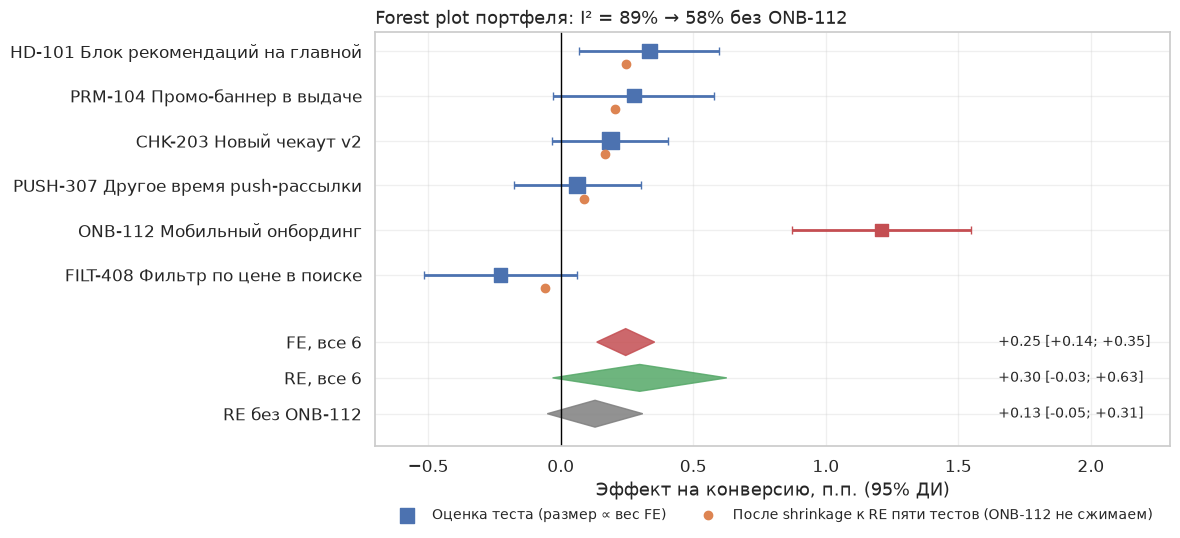

In [25]:
fig, ax = plt.subplots(figsize=(12, 5.6))
rows = np.arange(len(portfolio))[::-1] + 3
heterogeneous = portfolio['test_id'] == outlier
for y, e, s_, h in zip(rows, portfolio['effect'], portfolio['se'], heterogeneous):
    ax.errorbar(e, y, xerr=1.96 * s_, fmt='none', ecolor=RED if h else BLUE, capsize=3, lw=2)
ax.scatter(portfolio['effect'], rows, marker='s', s=30 + 120 * (portfolio['se'].min() / portfolio['se']) ** 2,
           color=[RED if h else BLUE for h in heterogeneous], zorder=3, label='Оценка теста (размер ∝ вес FE)')
ax.scatter(portfolio.loc[~heterogeneous, 'shrunk'], rows[~heterogeneous.to_numpy()] - 0.3, color=ORANGE, zorder=3,
           label='После shrinkage к RE пяти тестов (ONB-112 не сжимаем)')
for y, m, name, color in [(1.5, meta_all, 'FE, все 6', RED), (0.7, meta_all, 'RE, все 6', GREEN), (-0.1, meta_wo, f'RE без {outlier}', GRAY)]:
    centre = m['fe'] if name.startswith('FE') else m['re']
    half = 1.96 * (m['se_fe'] if name.startswith('FE') else m['se_re'])
    ax.fill([centre - half, centre, centre + half, centre], [y, y + 0.3, y, y - 0.3], color=color, alpha=0.85)
    ax.text(1.65, y, f"{centre:+.2f} [{centre - half:+.2f}; {centre + half:+.2f}]", va='center', fontsize=10)
ax.axvline(0, color='black', lw=1)
ax.set_yticks([*rows, 1.5, 0.7, -0.1], [f"{t} {n}" for t, n in zip(portfolio['test_id'], portfolio['name'])] + ['FE, все 6', 'RE, все 6', f'RE без {outlier}'])
ax.set_xlim(-0.7, 2.3)
ax.set_xlabel('Эффект на конверсию, п.п. (95% ДИ)')
ax.set_title(f"Forest plot портфеля: I² = {meta_all['i2']:.0%} → {meta_wo['i2']:.0%} без {outlier}", loc='left')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

### Ревью-борд и здоровье процесса

**Ревью-борд** — регулярная встреча, где команда защищает мемо перед коллегами. Его цель — не «одобрить», а поймать ошибки: правило задним числом, guardrail без non-inferiority, сегмент без поправки, деньги без допущений. Рубрика на 5 пунктов — в `memo_template.md`.

**Здоровье процесса** смотрим по портфелю, а не по отдельным тестам:

| Метрика | Что показывает | Тревожный сигнал |
| --- | --- | --- |
| Доля прошедших правило | оценка выше BE своего теста (правило встречи 1); при α = 0.5 против BE она выше доли значимых выигрышей | резкий рост между кварталами — проверьте, не менялись ли правила задним числом |
| Доля значимых выигрышей | p < 0.05 и эффект > 0 — так считают в отрасли | > 50% подозрительно, ищите p-hacking; у Microsoft значимо выигрывает около трети идей |
| Средний эффект внедрённых (после shrinkage) | реальная отдача портфеля | сумма «сырых» эффектов сильно больше суммы сжатых |
| Доля вредных и нулевых | идеи, от которых тест спас | 0% — нулевые тесты не доходят до базы знаний |
| Тесты с планом до запуска | дисциплина | любые решения «по факту» |
| I² портфеля | насколько тесты сравнимы | > 75%: портфель смешивает разные продукты или есть выброс |

Нулевой результат — тоже знание: он сужает ожидания и экономит трафик следующих тестов. Если в базу попадают только победы, мета-анализ завышает эффекты так же, как публикационное смещение в науке.

## 7. Мемо на страницу

Шаблон — `memo_template.md`. Структура:

1. **Решение в первой строке**: внедряем / не внедряем как есть / не внедряем — и почему одной фразой.
2. **Эффект** по OEC: оценка и 95% ДИ в метрике и в деньгах за горизонт.
3. **Порог** и правило решения, зафиксированные до запуска.
4. **Guardrail** — прошли ли non-inferiority; качество данных (SRM, очистка).
5. **Риски и допущения** — что должно быть правдой, чтобы деньги сошлись.
6. **Сегменты** — только преднамеченные; разведочные — как гипотезы.
7. **Что дальше** — следующий шаг, владелец, срок.

Функция `render_memo` собирает мемо по шаблону из словаря. Числа берутся из переменных анализа, а не переписываются руками: так мемо не разойдётся с расчётом.

In [26]:
def render_memo(m: dict) -> str:
    """Собирает мемо по структуре memo_template.md."""
    lines = [
        f"## {m['title']}",
        '',
        f"**Решение: {m['decision']}** — {m['why']}",
        '',
        '| | |',
        '| --- | --- |',
        f"| Эффект на OEC (конверсия) | {m['effect_pp']:+.2f} п.п., 95% ДИ [{m['ci_pp'][0]:+.2f}; {m['ci_pp'][1]:+.2f}] (≈ {m['effect_rel']:+.1%} относительных) |",
        f"| В деньгах за 12 мес., чистыми | {m['money_mln']:+.0f} млн ₽, 95% ДИ [{m['money_ci_mln'][0]:+.0f}; {m['money_ci_mln'][1]:+.0f}] |",
        f"| Порог решения | {m['break_even_pp']} п.п. (точка безубыточности) — правило до запуска: {m['rule']} |",
        f"| Guardrail | {m['guardrail']} |",
        f"| Вторичные метрики | {m['secondary']} |",
        f"| Качество данных | {m['data_quality']} |",
        '',
        '**Риски и допущения**',
        *[f"- {r}" for r in m['risks']],
        '',
        f"**Сегменты (только преднамеченные):** {m['segments']}",
        '',
        '**Что дальше**',
        *[f"{i}. {s}" for i, s in enumerate(m['next_steps'], 1)],
    ]
    return '\n'.join(lines)

**Вопрос.** Аналитик хочет добавить в мемо по чекауту разрез, где эффект на конверсию оказался самым большим: «владельцу будет интересно». Что ответить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Не добавлять как вывод. В дизайн-доке чекаута сегменты не заявлялись, значит, любой разрез — разведка. Лучший из нескольких разрезов переоценён (проклятие победителя), а без поправки «особый» сегмент находится часто: при 20 разрезах — в 64% случаев (раздел 5).

В мемо так и пишем: «преднамеченных сегментов не было, не отчитываемся; разведочные разрезы — только как гипотезы». Если разрез правда интересен — это гипотеза для отдельного подтверждающего теста с числом просмотренных разрезов в описании.

Рубрика ревью-борда даёт за это полный балл: честное «сегментов нет» лучше красивого «у мобильных +3%».

</details>

In [27]:
MEMO = {
    'title': (f"Новый чекаут · {df['date'].min()} — {df['date'].max()} · 80/20, "
              f"A = {spaced(counts['A'])}, B = {spaced(counts['B'])}"),
    'decision': DECISION,
    'why': 'конверсия выросла с запасом над порогом, но ошибки оплаты не доказали non-inferiority: чиним и подтверждаем.',
    'effect_rel': effect_pp / (100 * p_a),
    'rule': f"внедряем, если оценка > {BE_PP} п.п. и guardrail доказал non-inferiority (+{NI_MARGIN_PP} п.п.)",
    'effect_pp': effect_pp,
    'ci_pp': ci_pp,
    'money_mln': money_net / 1e6,
    'money_ci_mln': (money_ci[0] / 1e6, money_ci[1] / 1e6),
    'break_even_pp': BE_PP,
    'guardrail': (f"ошибки оплаты {guardrail['effect_pp']:+.3f} п.п. (≈ {guardrail['effect_pp']:+.2f}), "
                  f"верхняя граница {guardrail['upper_pp']:+.2f} п.п. "
                  f"при допустимых +{NI_MARGIN_PP} — **не прошёл**"),
    'secondary': (f"время на чекауте {results.loc['checkout_time_sec', 'effect']:+.1f} с (значимо после Холма); ".replace('-', '−')
                  + f"ARPU {results.loc['revenue', 'effect']:+.0f} ₽, незначимо (p = {results.loc['revenue', 'p_adj']:.2f})"),
    'data_quality': f"удалены дубли и пользователи в обеих группах ({spaced(len(raw) - len(df))} строк); SRM p = {srm_p:.2f}",
    'risks': [
        'Деньги — через конверсию при допущении «средний чек не меняется»; в тесте чек −0.5% (незначимо). По ARPU точечная оценка ≈ +79 млн ₽, ДИ накрывает ноль — нижняя оценка денег реалистичнее верхней.',
        'Ошибки оплаты могут бить по повторным покупкам и нагрузке на поддержку — в 14 днях теста это не видно.',
        'Эффект измерен за 2 недели: эффект новизны не исключён, после раскатки — мониторинг 4 недели.',
        f'Цена ожидания: ≈ {WEEK_COST_MLN:.1f} млн ₽ выручки в неделю (при относительном эффекте +{effect_pp / (100 * p_a):.0%}); фикс (1 нед.) + подтверждающий тест ({confirm_weeks} нед.) ≈ {WEEK_COST_MLN * (1 + confirm_weeks):.0f} млн ₽, поэтому фикс — приоритет.',
    ],
    'segments': 'в дизайн-доке не заявлялись, поэтому не отчитываемся; разведочные разрезы — только как гипотезы.',
    'next_steps': [
        'Найти и исправить причину роста ошибок оплаты (способ оплаты, платформа, банк) — команда платежей, 1 неделя.',
        (f'Подтверждающий тест 50/50 на {confirm_weeks} недели ({confirm_days} дн. трафика, {spaced(confirm_n)} польз.) '
         f'на мощность guardrail {CONFIRM_POWER} (граница +{NI_MARGIN_PP} п.п.) — по правилу эскалации из дизайн-дока '
         'встречи 2; правило решения записать до запуска — аналитик чекаута, старт сразу после фикса.'),
        'Занести тест в портфель с исходом «OEC выше порога, guardrail не прошёл» — аналитик чекаута, до квартального ревью-борда.',
    ],
}
memo_md = render_memo(MEMO)
display(Markdown(memo_md))

## Новый чекаут · 2026-09-07 — 2026-09-20 · 80/20, A = 83 878, B = 21 082

**Решение: не внедряем как есть** — конверсия выросла с запасом над порогом, но ошибки оплаты не доказали non-inferiority: чиним и подтверждаем.

| | |
| --- | --- |
| Эффект на OEC (конверсия) | +1.40 п.п., 95% ДИ [+0.71; +2.08] (≈ +2.0% относительных) |
| В деньгах за 12 мес., чистыми | +118 млн ₽, 95% ДИ [+48; +187] |
| Порог решения | 0.246 п.п. (точка безубыточности) — правило до запуска: внедряем, если оценка > 0.246 п.п. и guardrail доказал non-inferiority (+0.2 п.п.) |
| Guardrail | ошибки оплаты +0.198 п.п. (≈ +0.20), верхняя граница +0.38 п.п. при допустимых +0.2 — **не прошёл** |
| Вторичные метрики | время на чекауте −3.2 с (значимо после Холма); ARPU +38 ₽, незначимо (p = 0.13) |
| Качество данных | удалены дубли и пользователи в обеих группах (370 строк); SRM p = 0.49 |

**Риски и допущения**
- Деньги — через конверсию при допущении «средний чек не меняется»; в тесте чек −0.5% (незначимо). По ARPU точечная оценка ≈ +79 млн ₽, ДИ накрывает ноль — нижняя оценка денег реалистичнее верхней.
- Ошибки оплаты могут бить по повторным покупкам и нагрузке на поддержку — в 14 днях теста это не видно.
- Эффект измерен за 2 недели: эффект новизны не исключён, после раскатки — мониторинг 4 недели.
- Цена ожидания: ≈ 2.7 млн ₽ выручки в неделю (при относительном эффекте +2%); фикс (1 нед.) + подтверждающий тест (4 нед.) ≈ 14 млн ₽, поэтому фикс — приоритет.

**Сегменты (только преднамеченные):** в дизайн-доке не заявлялись, поэтому не отчитываемся; разведочные разрезы — только как гипотезы.

**Что дальше**
1. Найти и исправить причину роста ошибок оплаты (способ оплаты, платформа, банк) — команда платежей, 1 неделя.
2. Подтверждающий тест 50/50 на 4 недели (23 дн. трафика, 167 699 польз.) на мощность guardrail 0.9 (граница +0.2 п.п.) — по правилу эскалации из дизайн-дока встречи 2; правило решения записать до запуска — аналитик чекаута, старт сразу после фикса.
3. Занести тест в портфель с исходом «OEC выше порога, guardrail не прошёл» — аналитик чекаута, до квартального ревью-борда.

### Самопроверка по рубрике ревью-борда

Рубрика — в `memo_template.md`: 0 — нет, 1 — частично, 2 — да; готово при сумме ≥ 8 и без нулей. Оценка мемо выше:

| № | Критерий | Балл | Почему |
| :---: | --- | :---: | --- |
| 1 | Решение и правило | 2 | Решение — первой строкой после заголовка; правило записано до запуска и приведено в строке «Порог» |
| 2 | Эффект против порога | 2 | OEC с ДИ в п.п. и в деньгах одной формулой; сравнение с BE 0.246, а не с нулём |
| 3 | Доверие к данным и guardrail | 2 | SRM и очистка указаны; guardrail — non-inferiority с границей +0.2; вторичные — с Холмом и не влияют на решение |
| 4 | Сегменты без p-hacking | 2 | Преднамеченных сегментов нет — так и написано; разведка не выдана за вывод |
| 5 | Риски и следующий шаг | 2 | Допущение о чеке и ARPU-сверка в рисках; у каждого шага владелец и срок; тест идёт в портфель |

## 8. Итог и как было на самом деле

* **Чекаут по лестнице решения.** Данные чистые (SRM p = 0.49) → конверсия +1.40 п.п. [+0.71; +2.08] → +118 млн ₽ [+48; +187] → выше BE 0.246 с запасом → ошибки оплаты: верхняя граница +0.38 > +0.2, не доказано → **не внедряем как есть**. Двусторонний тест против нуля пропустил бы баг.
* **Ловушки.** Средний чек в B −0.5% при ARPU +1.5% — разные популяции, а не вред. Смена сплита во времени переворачивает знак эффекта, если не стратифицировать.
* **Сегменты.** 8 из 15 «значимы» против нуля, но это эхо общего эффекта. Взаимодействие после Холма — только у mobile/new, это гипотеза для подтверждающего теста. A/A: хотя бы один ложный сегмент — в трети прогонов.
* **Портфель.** $I^2$ = 89% из-за ONB-112; без него — 58% и +0.13 п.п. в среднем. Нулевой тест — знание, а не провал. Своё правило прошли 3 из 6, значимо выиграли 2 из 6; сжатые оценки победителей ниже сырых почти на треть: с +0.31 до +0.22 п.п.
* **Артефакт** — мемо по шаблону `memo_template.md` (раздел 7) и рубрика ревью-борда.

### Как было на самом деле (истина из генераторов `data/generate_*.py`)

Раскрываем только сейчас, после всех решений.

* **Чекаут:** конверсия 70.0% → 71.1% (+1.1 п.п.; наша оценка +1.40 в пределах ДИ), ошибки оплаты 2.00% → 2.25% (+0.25 п.п. — **хуже** границы non-inferiority). Средний чек (выручка на заказ) не менялся, время на чекауте −2%. Решение «не внедряем как есть» было верным.
* **Горящие предложения:** настоящая гетерогенность — по `device` (мобильным эффект ×2.0, вебу ×0.6) и по новизне (новичкам ×2.4, остальным ×0.68). Значит, mobile/new — реальный сегмент. Сегмент активности (`segment`) **пустой**: множитель 1.0 у low, mid и high. Его «значимость» — эхо общего эффекта и доли новичков в low. Эффект затухает: на когорте первого дня +1.0 п.п., долгосрочный +0.2 п.п. (полупериод около 3 дней). Средние +0.35 п.п. за 28 дней — смесь новизны и долгосрочного эффекта.
* **Портфель:** истинные эффекты 0.32, 0.28, 0.19, 0.06, **1.20** (ONB-112) и −0.22 п.п. Нулевой — PUSH-307, гетерогенный — ONB-112, вредный — FILT-408.